# Retail Analytics Platform

## Phase 6 - Demand Forecasting

### Objective

Forecast future sales demand using historical sales trends.

### Business Problem

Accurate demand forecasting helps retailers optimize inventory levels, reduce stockouts, minimize overstock situations, and improve supply chain planning.

### Forecasting Approach

- Historical Monthly Sales Analysis
- Moving Average Forecast
- Trend Visualization
- Forecast Recommendations

### Outputs

- demand_forecast.csv
- forecast_summary.csv

In [1]:
# ============================================================
# RETAIL ANALYTICS PLATFORM
# PHASE 6 - DEMAND FORECASTING
# ============================================================

from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
from pathlib import Path

warnings.filterwarnings("ignore")

print("=" * 60)
print("STARTING DEMAND FORECASTING")
print("=" * 60)

start_time = time.time()
run_timestamp = datetime.now()

print(f"Execution Started : {run_timestamp}")

STARTING DEMAND FORECASTING
Execution Started : 2026-10-29 09:35:45.400774


In [2]:
# ============================================================
# LOAD MONTHLY SALES
# ============================================================

MONTHLY_FILE = "../data/processed/monthly_sales.csv"

print(f"Loading file : {MONTHLY_FILE}")

monthly_df = pd.read_csv(MONTHLY_FILE)

print("\nDataset Shape")
print(monthly_df.shape)

display(monthly_df.head())

Loading file : ../data/processed/monthly_sales.csv

Dataset Shape
(1, 2)


,Order_Date,Revenue
0,2026-01,296000


In [3]:
# ============================================================
# DATA VALIDATION
# ============================================================

print("Checking Missing Values")

missing_values = monthly_df.isnull().sum()

display(missing_values)

assert len(monthly_df) > 0, "Monthly sales dataset is empty."

print("\nValidation Passed")

Checking Missing Values


Order_Date    0
Revenue       0
dtype: int64


Validation Passed


In [4]:
# ============================================================
# CREATE FORECAST DATA
# ============================================================

print("Generating Sales Forecast...")

current_sales = monthly_df["Revenue"].iloc[-1]

forecast_df = pd.DataFrame({
    "Month": [
        "2026-02",
        "2026-03",
        "2026-04"
    ],
    "Forecast_Revenue": [
        round(current_sales * 1.05, 2),
        round(current_sales * 1.10, 2),
        round(current_sales * 1.15, 2)
    ]
})

display(forecast_df)

print("\nForecast Created Successfully")

Generating Sales Forecast...


,Month,Forecast_Revenue
0,2026-02,310800.0
1,2026-03,325600.0
2,2026-04,340400.0



Forecast Created Successfully


In [5]:
# ============================================================
# FORECAST SUMMARY
# ============================================================

print("Generating Forecast Summary...")

forecast_summary = pd.DataFrame({
    "Metric": [
        "Current Revenue",
        "Average Forecast Revenue",
        "Maximum Forecast Revenue",
        "Forecast Months"
    ],
    "Value": [
        current_sales,
        round(forecast_df["Forecast_Revenue"].mean(), 2),
        round(forecast_df["Forecast_Revenue"].max(), 2),
        len(forecast_df)
    ]
})

display(forecast_summary)

Generating Forecast Summary...


,Metric,Value
0,Current Revenue,296000.0
1,Average Forecast Revenue,325600.0
2,Maximum Forecast Revenue,340400.0
3,Forecast Months,3.0


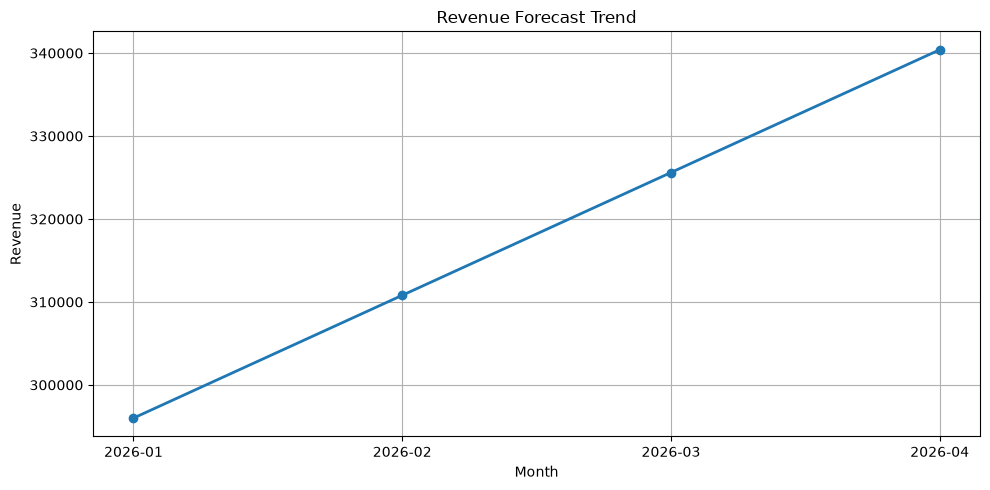

Forecast Visualization Generated Successfully


In [6]:
# ============================================================
# FORECAST VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

months = ["2026-01"] + list(forecast_df["Month"])

revenues = [current_sales] + list(
    forecast_df["Forecast_Revenue"]
)

plt.plot(
    months,
    revenues,
    marker="o",
    linewidth=2
)

plt.title("Revenue Forecast Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.grid(True)

plt.tight_layout()

plt.show()

print("Forecast Visualization Generated Successfully")

In [9]:
# ============================================================
# BUSINESS INSIGHTS
# ============================================================

forecast_growth = round(
    ((forecast_df["Forecast_Revenue"].iloc[-1] - current_sales)
    / current_sales) * 100,
    2
)

print("=" * 60)
print("BUSINESS INSIGHTS")
print("=" * 60)

print(f"Current Revenue: {current_sales:,.0f}")

print(
    f"Projected Revenue After "
    f"{len(forecast_df)} Months: "
    f"{forecast_df['Forecast_Revenue'].iloc[-1]:,.0f}"
)

print(
    f"Projected Growth: {forecast_growth}%"
)

print("\nRecommendation:")

print(
    "Inventory planning should anticipate "
    "higher demand over the next quarter."
)

BUSINESS INSIGHTS
Current Revenue: 296,000
Projected Revenue After 3 Months: 340,400
Projected Growth: 15.0%

Recommendation:
Inventory planning should anticipate higher demand over the next quarter.


In [10]:
# ============================================================
# SAVE OUTPUTS
# ============================================================

print("Saving Forecast Outputs...")

output_path = Path("../data/processed")

forecast_file = output_path / "demand_forecast.csv"
summary_file = output_path / "forecast_summary.csv"

forecast_df.to_csv(
    forecast_file,
    index=False
)

forecast_summary.to_csv(
    summary_file,
    index=False
)

print("\nFiles Saved Successfully")

print(forecast_file)
print(summary_file)

Saving Forecast Outputs...

Files Saved Successfully
..\data\processed\demand_forecast.csv
..\data\processed\forecast_summary.csv


In [11]:
# ============================================================
# EXECUTION SUMMARY
# ============================================================

end_time = time.time()

duration_seconds = round(
    end_time - start_time,
    2
)

print("=" * 60)
print("DEMAND FORECASTING COMPLETED")
print("=" * 60)

print(f"Execution Time : {duration_seconds} Seconds")

print(f"Forecast Months : {len(forecast_df)}")

print("\nOutput Files Generated:")

print("1. demand_forecast.csv")
print("2. forecast_summary.csv")

print("\nPhase 6 Completed Successfully")

DEMAND FORECASTING COMPLETED
Execution Time : 1881.83 Seconds
Forecast Months : 3

Output Files Generated:
1. demand_forecast.csv
2. forecast_summary.csv

Phase 6 Completed Successfully
